# VC · Práctica 5 — 02. Entrenamiento de CNN Propia en PyTorch (FER-2013)

Entrena `CNNFer` (4 bloques convolucionales con *data augmentation* facial integrado, `class_weight` suavizado, `label_smoothing=0.1`, `AdamW`, `ReduceLROnPlateau` y `EarlyStopping`) reutilizando `fer_lib/`.

## Configuración, semilla e hiperparámetros

In [1]:
import sys
from pathlib import Path

P5_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "fer_lib").is_dir())
if str(P5_ROOT) not in sys.path:
    sys.path.insert(0, str(P5_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, f1_score

from fer_lib.config import CNN_CKPT, CNN_DIR, SEED, TRAIN_DIR, VAL_SIZE, save_json
from fer_lib.data import compute_smoothed_class_weights, load_split, make_loader, split_train_val
from fer_lib.evaluation import plot_confusion, predict_probs
from fer_lib.models import CNNFer, load_checkpoint
from fer_lib.training import fit_cnn, set_seed

set_seed(SEED)
CNN_DIR.mkdir(parents=True, exist_ok=True)
MODEL_NAME = f"cnn_fer_torch_seed{SEED}"
MODEL_PATH = CNN_CKPT

BALANCE_TRAIN = False
PER_CLASS_CAP = None
FILTERS = [48, 96, 192, 384]
DROPOUTS = [0.05, 0.10, 0.15, 0.20]
HEAD_UNITS = 256
HEAD_DROPOUT = 0.40
AUG_ROTATION_DEG = 10.8
AUG_ZOOM = 0.10

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.10
EPOCHS, BATCH = 80, 64
ES_PATIENCE, LR_PATIENCE = 12, 4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert TRAIN_DIR.is_dir(), f"No encuentro train/ en {TRAIN_DIR.parent}"
print(
    f"Training seed: {SEED} | PyTorch {torch.__version__} | device: {device}"
    + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
)

Training seed: 42 | PyTorch 2.15.0+cu132 | device: cuda (NVIDIA GeForce RTX 3060 Ti)


## Carga de datos, validación estratificada (80/20) y pesos de clase

In [2]:
X_full, y_full, CLASS_NAMES = load_split(TRAIN_DIR)
N_CLASSES = len(CLASS_NAMES)
X_tr, X_val, y_tr, y_val = split_train_val(X_full, y_full, val_size=VAL_SIZE, seed=SEED)

cw, cw_tensor = compute_smoothed_class_weights(y_tr, N_CLASSES, power=0.5)
print(f"train: {len(y_tr)} | val: {len(y_val)}")
print(pd.DataFrame({
    "train": np.bincount(y_tr, minlength=N_CLASSES),
    "val": np.bincount(y_val, minlength=N_CLASSES),
    "class_weight": np.round(cw, 2),
}, index=CLASS_NAMES))

train_loader = make_loader(X_tr, y_tr, batch_size=BATCH, shuffle=True, seed=SEED, pin_memory=(device.type == "cuda"))
val_loader = make_loader(X_val, y_val, batch_size=256, shuffle=False, seed=SEED, pin_memory=(device.type == "cuda"))

train/angry:   0%|          | 0/3995 [00:00<?, ?it/s]

train/disgusted:   0%|          | 0/436 [00:00<?, ?it/s]

train/fearful:   0%|          | 0/4097 [00:00<?, ?it/s]

train/happy:   0%|          | 0/7215 [00:00<?, ?it/s]

train/neutral:   0%|          | 0/4965 [00:00<?, ?it/s]

train/sad:   0%|          | 0/4830 [00:00<?, ?it/s]

train/surprised:   0%|          | 0/3171 [00:00<?, ?it/s]

train: 22967 | val: 5742
           train   val  class_weight
angry       3196   799          0.81
disgusted    349    87          2.44
fearful     3277   820          0.80
happy       5772  1443          0.60
neutral     3972   993          0.72
sad         3864   966          0.73
surprised   2537   634          0.90


## Instanciación del modelo `CNNFer`

In [3]:
set_seed(SEED)
arch_cfg = {
    "in_channels": 1,
    "n_classes": N_CLASSES,
    "filters": FILTERS,
    "dropouts": DROPOUTS,
    "head_units": HEAD_UNITS,
    "head_dropout": HEAD_DROPOUT,
    "aug_rotation_deg": AUG_ROTATION_DEG,
    "aug_zoom": AUG_ZOOM,
}
model = CNNFer(**arch_cfg).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Total params: {total_params:,}")

CNNFer(
  (augment): Sequential(
    (0): RandomHorizontalFlip(p=0.5)
    (1): RandomAffine(degrees=[-10.8, 10.8], translate=(0.08, 0.08), scale=(0.9, 1.1), interpolation=nearest, fill=0)
    (2): ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2))
    (3): RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3), value=[0.0], inplace=False)
  )
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(1, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.05, i

## Entrenamiento

In [4]:
criterion = nn.CrossEntropyLoss(weight=cw_tensor.to(device), label_smoothing=LABEL_SMOOTHING)
history, best_ep, train_minutes = fit_cnn(
    model,
    train_loader,
    val_loader,
    criterion,
    device,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    lr_patience=LR_PATIENCE,
    es_patience=ES_PATIENCE,
)

Epoch 01/80 - 9.4s - loss: 1.9998 - accuracy: 0.2223 - val_loss: 1.9622 - val_accuracy: 0.2680 - lr: 0.001000
Epoch 02/80 - 8.6s - loss: 1.8889 - accuracy: 0.3072 - val_loss: 1.7417 - val_accuracy: 0.4039 - lr: 0.001000
Epoch 03/80 - 8.2s - loss: 1.7387 - accuracy: 0.4178 - val_loss: 1.6570 - val_accuracy: 0.4469 - lr: 0.001000
Epoch 04/80 - 8.6s - loss: 1.6641 - accuracy: 0.4549 - val_loss: 1.5508 - val_accuracy: 0.5165 - lr: 0.001000
Epoch 05/80 - 8.5s - loss: 1.6001 - accuracy: 0.4926 - val_loss: 1.5584 - val_accuracy: 0.5214 - lr: 0.001000
Epoch 06/80 - 8.5s - loss: 1.5640 - accuracy: 0.5143 - val_loss: 1.5277 - val_accuracy: 0.5078 - lr: 0.001000
Epoch 07/80 - 8.6s - loss: 1.5304 - accuracy: 0.5287 - val_loss: 1.4730 - val_accuracy: 0.5432 - lr: 0.001000
Epoch 08/80 - 8.6s - loss: 1.5063 - accuracy: 0.5440 - val_loss: 1.4342 - val_accuracy: 0.5589 - lr: 0.001000
Epoch 09/80 - 8.6s - loss: 1.4843 - accuracy: 0.5534 - val_loss: 1.4165 - val_accuracy: 0.5700 - lr: 0.001000
Epoch 10/8

## Curvas y evaluación en validación (con TTA)

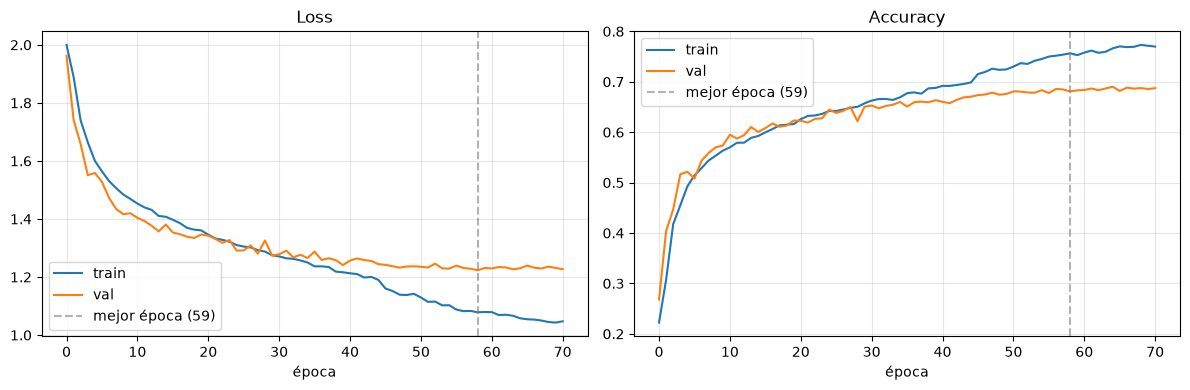

Mejor época: 59 | val_loss=1.2233 | val_accuracy=0.6808


In [5]:
h = history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title("Loss")
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val"); ax[1].set_title("Accuracy")
for a in ax:
    a.axvline(best_ep, color="gray", ls="--", alpha=.6, label=f"mejor época ({best_ep + 1})")
    a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Mejor época: {best_ep + 1} | val_loss={h['val_loss'][best_ep]:.4f} | val_accuracy={h['val_accuracy'][best_ep]:.4f}")

Validación (TTA) -> accuracy=0.6897 | F1-macro=0.6724

              precision    recall  f1-score   support

       angry       0.61      0.58      0.60       799
   disgusted       0.64      0.72      0.68        87
     fearful       0.56      0.55      0.55       820
       happy       0.88      0.88      0.88      1443
     neutral       0.62      0.71      0.66       993
         sad       0.60      0.50      0.54       966
   surprised       0.76      0.83      0.79       634

    accuracy                           0.69      5742
   macro avg       0.67      0.68      0.67      5742
weighted avg       0.69      0.69      0.69      5742



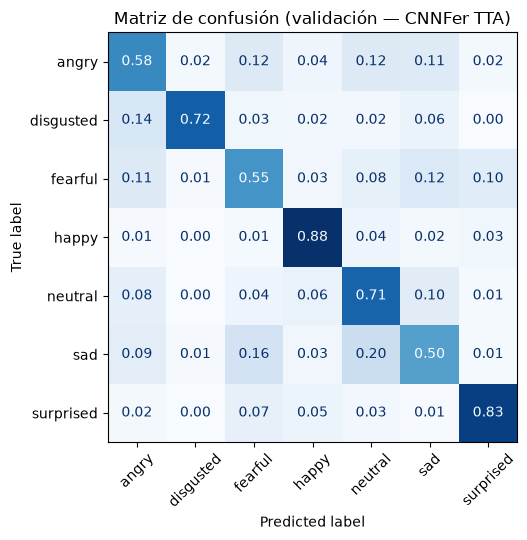

In [6]:
p_val = predict_probs(model, X_val, device=device, batch_size=256, use_tta=True)
y_pred_val = p_val.argmax(1)
val_acc_tta = float(np.mean(y_pred_val == y_val))
val_f1_macro = float(f1_score(y_val, y_pred_val, average="macro"))
print(f"Validación (TTA) -> accuracy={val_acc_tta:.4f} | F1-macro={val_f1_macro:.4f}\n")
print(classification_report(y_val, y_pred_val, target_names=CLASS_NAMES, zero_division=0))

plot_confusion(y_val, y_pred_val, CLASS_NAMES, title="Matriz de confusión (validación — CNNFer TTA)", figsize=(6, 5.5))

### Análisis de `CNNFer`
La arquitectura `CNNFer` ($2.74\text{ M}$ de parámetros) integra cuatro bloques convolucionales con normalización por lotes (*BatchNorm*), *Dropout2d* progresivo ($0.05 \to 0.20$) y *Global Average Pooling* para limitar la sobreparametrización en imágenes de $48\times 48$ píxeles. La combinación de pesos de clase suavizados ($w_c^{0.5}$) y *label smoothing* ($\epsilon = 0.10$) estabiliza la convergencia frente al desbalanceo extremo de `disgusted` (F1 = 0.68 en validación pese a representar solo el $1.5\%$ de los datos).

El entrenamiento converge de forma estable hasta la época 59 (`val_loss = 1.2233`, `val_accuracy = 0.6808`) activándose *Early Stopping* en la época 71. La aplicación de *Test-Time Augmentation* (promediado con reflejo horizontal) incrementa la exactitud en validación hasta **68.97 %** y el F1-macro hasta **67.24 %**, confirmando que la simetría bilateral del rostro aporta una regularización efectiva en inferencia.


## Guardado y verificación de recarga

In [7]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "arch": arch_cfg,
}
torch.save(checkpoint, MODEL_PATH)
save_json(CLASS_NAMES, CNN_DIR / "class_names.json")
pd.DataFrame(history).to_csv(CNN_DIR / f"{MODEL_NAME}_history.csv", index=False)

config = dict(
    framework="pytorch",
    seed=SEED,
    balance_train=BALANCE_TRAIN,
    per_class_cap=PER_CLASS_CAP,
    **{k: v for k, v in arch_cfg.items() if k not in ("in_channels", "n_classes")},
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    label_smoothing=LABEL_SMOOTHING,
    epochs_run=len(history["loss"]),
    best_epoch=best_ep + 1,
    val_loss=float(history["val_loss"][best_ep]),
    val_accuracy=val_acc_tta,
    val_f1_macro=val_f1_macro,
    train_minutes=round(train_minutes, 1),
)
save_json(config, CNN_DIR / f"{MODEL_NAME}_config.json")

reloaded, _, _ = load_checkpoint(MODEL_PATH, device=device)
p_orig = predict_probs(model, X_val[:64], device=device, use_tta=True)
p_rel = predict_probs(reloaded, X_val[:64], device=device, use_tta=True)
same = np.allclose(p_rel, p_orig, atol=1e-5)
print("Modelo guardado en:", MODEL_PATH, "| recarga OK:", same)
print(json.dumps(config, indent=2))

Modelo guardado en: /home/cris/Proyectos/computer-vision/P5/outputs_p5/models/v1_CNN_torch/cnn_fer_torch_seed42.pt | recarga OK: True
{
  "framework": "pytorch",
  "seed": 42,
  "balance_train": false,
  "per_class_cap": null,
  "filters": [
    48,
    96,
    192,
    384
  ],
  "dropouts": [
    0.05,
    0.1,
    0.15,
    0.2
  ],
  "head_units": 256,
  "head_dropout": 0.4,
  "aug_rotation_deg": 10.8,
  "aug_zoom": 0.1,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "label_smoothing": 0.1,
  "epochs_run": 71,
  "best_epoch": 59,
  "val_loss": 1.2233392629254698,
  "val_accuracy": 0.6896551724137931,
  "val_f1_macro": 0.6723677445752182,
  "train_minutes": 10.2
}
